# Laboratorio de Simulación Computacional
## Práctica N.º 04 · Generación de Variables Aleatorias Continuas

**Universidad de los Llanos** · Escuela de Ingeniería · Simulación Computacional

**Estudiante:** Luciana A. Belandria A.

**Codigo:** 160005005

# 5. Procedimiento o metodología



### Librerías

In [1]:
import math
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

### Generador congruencial mixto

In [2]:
def genran(a, c, m, xant):
    xsig = (a * xant + c) % m
    usig = xsig / m
    return [xsig, usig]

def genranN(a, c, m, x0, N):
    xant = x0
    I = []; X = []; U = []
    for t in range(1, N + 1):
        [xi, ui] = genran(a, c, m, xant)
        I.append(t); X.append(xi); U.append(ui)
        xant = xi
    return [I, X, U]

def showValues(I, X, U, nmax=None):
    print("i\tXi\tUi")
    top = len(X) if nmax is None else min(len(X), nmax)
    for t in range(0, top):
        print("%d\t%d\t%2.4f" % (I[t], X[t], U[t]), sep=' ', end='\n')

Los métodos de rechazo y los procesos de Poisson consumen una cantidad variable de números aleatorios. Por eso se genera una sola secuencia larga con `genranN` y la función `nextU()` va entregando sus valores en orden, sin repetir ninguno.

In [3]:
x0, a_g, c_g, m_g = 2391, 25214903917, 11, 2**48
N_U = 1000000

I, X, U_seq = genranN(a_g, c_g, m_g, x0, N_U)
showValues(I, X, U_seq, nmax=10)

pos = 0
def nextU():
    global pos
    u = U_seq[pos]
    pos += 1
    return u

i	Xi	Ui
1	60288835265558	0.2142
2	209685691965801	0.7450
3	186049190006720	0.6610
4	213779903198411	0.7595
5	220526493523066	0.7835
6	110461497900029	0.3924
7	185977705830596	0.6607
8	252890576593791	0.8984
9	99402896324382	0.3532
10	204148328590289	0.7253


### Verificación de uniformidad y aleatoriedad

Se aplican la prueba Chi² (uniformidad) y la prueba de rachas (aleatoriedad) a los primeros 10000 números de la secuencia, con $k=10$ clases y $\alpha=0.05$.

In [4]:
def pruebaChi2(U, k=10, alpha=0.05):
    n = len(U)
    F, _ = np.histogram(U, bins=k, range=(0, 1))
    E = n / k
    chisq = np.sum(((F - E) ** 2) / E)
    Tval = stats.chi2.ppf(1 - alpha, k - 1)
    return chisq, Tval, bool(chisq <= Tval)

def pruebaRachas(U, alpha=0.05):
    n = len(U)
    A = np.zeros(n - 1)
    for i in range(1, n):
        A[i - 1] = 0 if U[i - 1] > U[i] else 1
    A2 = np.array((A == 1))
    sw = (A2[:-1] ^ A2[1:])
    isw = list(np.arange(len(sw))[sw]); isw.insert(0, -1); isw = np.array(isw)
    L = isw[1:(len(isw))] - isw[0:(len(isw) - 1)]
    R = len(L)
    Z = (R - ((2 * n - 1) / 3)) / (np.sqrt((16 * n - 29) / (90)))
    Zt = stats.norm.ppf((1 + (1 - alpha)) / 2)
    return R, Z, Zt, bool(abs(Z) <= Zt)

k = 10
alpha = 0.05
U_test = U_seq[:10000]

chisq, chiT, ok_chi = pruebaChi2(U_test, k=k, alpha=alpha)
R, Z, Zt, ok_rac = pruebaRachas(U_test, alpha=alpha)
print("Chi2  = %.4f  vs crit %.4f  -> uniformidad: %s" % (chisq, chiT, "acepta" if ok_chi else "RECHAZA"))
print("Rachas R=%d Z=%.4f vs %.4f  -> aleatoriedad: %s" % (R, Z, Zt, "acepta" if ok_rac else "RECHAZA"))

Chi2  = 10.6000  vs crit 16.9190  -> uniformidad: acepta
Rachas R=6699 Z=0.7748 vs 1.9600  -> aleatoriedad: acepta


### Función para comparar histograma y densidad teórica

In [5]:
def hist_vs_teorica(muestras, x, fx, titulo, bins=30, xlabel="x"):
    plt.figure(figsize=(8, 4.5))
    plt.hist(muestras, bins=bins, density=True, alpha=0.6, edgecolor="black", label="Valores generados")
    plt.plot(x, fx, "r-", lw=2, label="Densidad teórica")
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel("Densidad")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

def resumen(muestras, media_teo=None):
    txt = f"n = {len(muestras)} | media muestral = {np.mean(muestras):.4f}"
    if media_teo is not None:
        txt += f" | media teórica = {media_teo:.4f}"
    print(txt)

## 5.1. Generación de variables aleatorias continuas

En cada caso se generan los primeros **1000 valores** y se compara su histograma con la densidad teórica.

### a. Densidad exponencial truncada en [0, 1]

$$f(x)=\frac{e^x}{e-1},\qquad 0\le x\le 1$$

**Transformada inversa.** La función de distribución es

$$F(x)=\int_0^x \frac{e^y}{e-1}\,dy=\frac{e^x-1}{e-1}.$$

Haciendo $u=F(x)$ se obtiene $e^x=1+(e-1)u$, de donde

$$X=F^{-1}(U)=\log\big(1+(e-1)U\big).$$

n = 1000 | media muestral = 0.5842 | media teórica = 0.5820
Primeros 10 valores: [0.3134 0.8242 0.7588 0.8351 0.8528 0.5154 0.7586 0.9337 0.4743 0.8093]


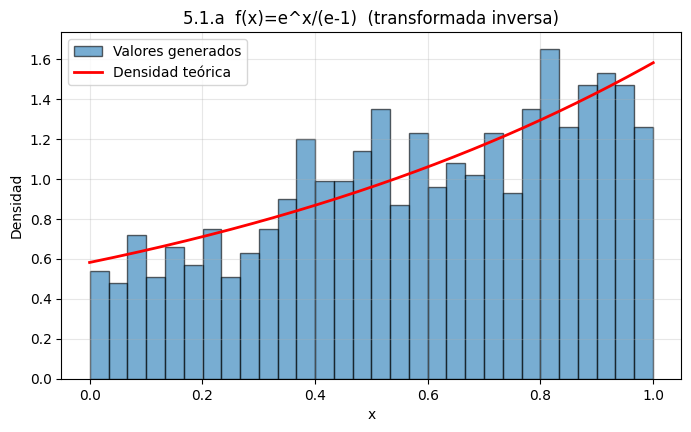

In [6]:
def gen_a_inversa():
    return math.log(1 + (math.e - 1) * nextU())

n = 1000
xa = np.array([gen_a_inversa() for _ in range(n)])

x = np.linspace(0, 1, 300)
fa = np.exp(x) / (np.e - 1)
media_a = 1 / (np.e - 1)
resumen(xa, media_a)
print("Primeros 10 valores:", np.round(xa[:10], 4))
hist_vs_teorica(xa, x, fa, "5.1.a  f(x)=e^x/(e-1)  (transformada inversa)")

**Alternativa por el método del rechazo.** Con $g(x)=1$ en $(0,1)$, el cociente $f(x)/g(x)=e^x/(e-1)$ es creciente, así que su máximo está en $x=1$:

$$c=\frac{e}{e-1}\approx 1.582,\qquad \frac{f(x)}{c\,g(x)}=e^{x-1}.$$

Se generan $U_1,U_2$ y se acepta $X=U_1$ si $U_2\le e^{U_1-1}$. El número de iteraciones es geométrico con media $c$.

n = 1000 | media muestral = 0.5811 | media teórica = 0.5820
Iteraciones promedio = 1.6030 | c teórico = 1.5820


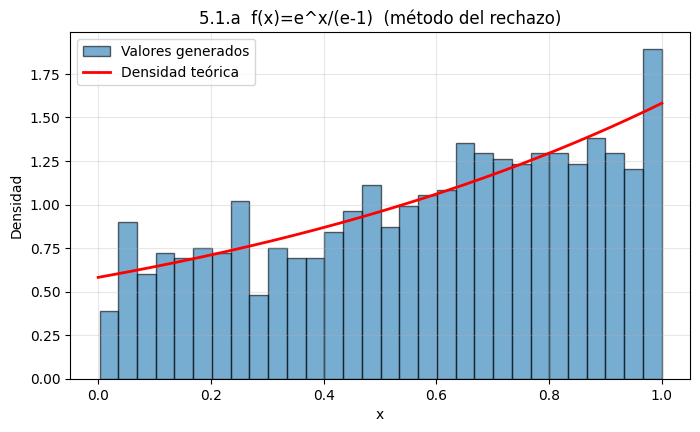

In [7]:
def gen_a_rechazo():
    it = 0
    while True:
        it += 1
        u1, u2 = nextU(), nextU()
        if u2 <= math.exp(u1 - 1):
            return u1, it

res = [gen_a_rechazo() for _ in range(n)]
xa_r = np.array([r[0] for r in res])
it_a = np.array([r[1] for r in res])
resumen(xa_r, media_a)
print(f"Iteraciones promedio = {it_a.mean():.4f} | c teórico = {np.e/(np.e-1):.4f}")
hist_vs_teorica(xa_r, x, fa, "5.1.a  f(x)=e^x/(e-1)  (método del rechazo)")

### b. Densidad definida por tramos

$$f(x)=\begin{cases}\dfrac{x-2}{2} & 2\le x\le 3\\[2mm] \dfrac{2-x/3}{2} & 3\le x\le 6\end{cases}$$

**Transformada inversa.** Integrando por tramos:

- Para $2\le x\le 3$: $\;F(x)=\displaystyle\int_2^x\frac{y-2}{2}dy=\frac{(x-2)^2}{4}$, con $F(3)=\tfrac14$.
- Para $3\le x\le 6$: $\;F(x)=\tfrac14+\displaystyle\int_3^x\frac{2-y/3}{2}dy=x-\frac{x^2}{12}-2$, con $F(6)=1$.

Invirtiendo cada tramo:

- Si $U\le \tfrac14$: $\;(x-2)^2=4U\Rightarrow X=2+2\sqrt{U}$.
- Si $U>\tfrac14$: $\;x^2-12x+12(2+U)=0\Rightarrow X=6-2\sqrt{3(1-U)}$ (la raíz que cae en $[3,6]$).

n = 1000 | media muestral = 3.7178 | media teórica = 3.6667
Primeros 10 valores: [3.7554 4.537  3.5044 4.5974 4.7748 3.2169 3.8179 3.7696 5.25   4.2471]


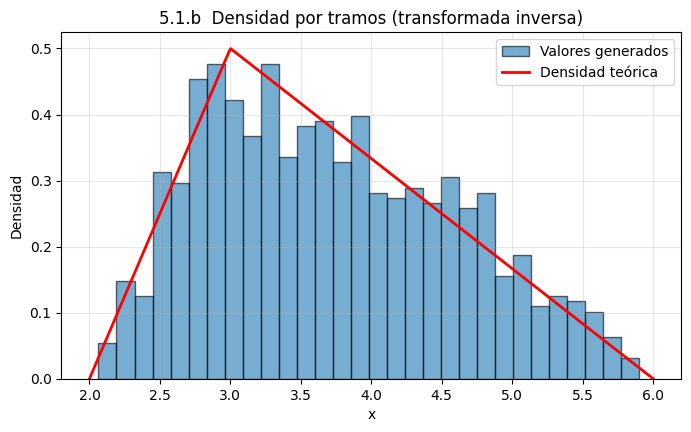

In [8]:
def fb(x):
    x = np.asarray(x, dtype=float)
    return np.where((x >= 2) & (x <= 3), (x - 2) / 2,
           np.where((x > 3) & (x <= 6), (2 - x / 3) / 2, 0.0))

def gen_b_inversa():
    u = nextU()
    if u <= 0.25:
        return 2 + 2 * math.sqrt(u)
    return 6 - 2 * math.sqrt(3 * (1 - u))

xb = np.array([gen_b_inversa() for _ in range(n)])
x = np.linspace(2, 6, 400)
media_b = 11 / 3
resumen(xb, media_b)
print("Primeros 10 valores:", np.round(xb[:10], 4))
hist_vs_teorica(xb, x, fb(x), "5.1.b  Densidad por tramos (transformada inversa)")

**Alternativa por el método del rechazo.** Con $g(x)=\tfrac14$ (uniforme en $(2,6)$), el máximo de $f$ es $f(3)=\tfrac12$, luego

$$c=\max\frac{f(x)}{g(x)}=\frac{1/2}{1/4}=2,\qquad \frac{f(Y)}{c\,g(Y)}=2f(Y).$$

Se genera $Y=2+4U_1$ y se acepta si $U_2\le 2f(Y)$.

n = 1000 | media muestral = 3.6112 | media teórica = 3.6667
Iteraciones promedio = 2.0110 | c teórico = 2


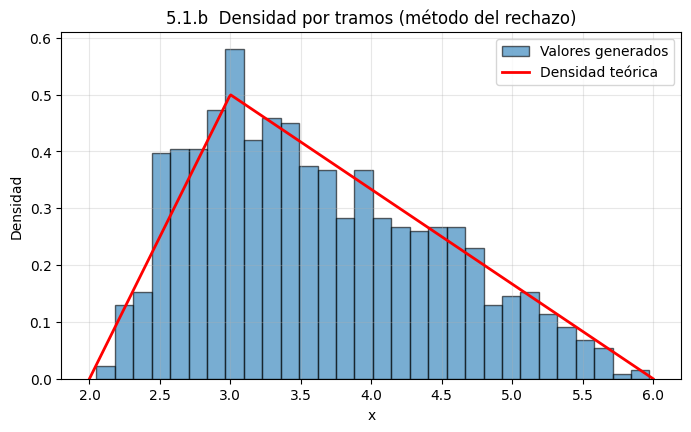

In [ ]:
def gen_b_rechazo():
    it = 0
    while True:
        it += 1
        y = 2 + 4 * nextU()
        if nextU() <= 2 * float(fb(y)):
            return y, it

res = [gen_b_rechazo() for _ in range(n)]
xb_r = np.array([r[0] for r in res])
it_b = np.array([r[1] for r in res])
resumen(xb_r, media_b)
print(f"Iteraciones promedio = {it_b.mean():.4f} | c teórico = 2")
hist_vs_teorica(xb_r, x, fb(x), "5.1.b  Densidad por tramos (método del rechazo)")

### c. Función de distribución cuadrática

$$F(x)=\frac{x^2+x}{2},\qquad 0\le x\le 1$$

**Transformada inversa.** Haciendo $u=F(x)$ queda $x^2+x-2u=0$, y tomando la raíz positiva

$$X=F^{-1}(U)=\frac{-1+\sqrt{1+8U}}{2}.$$

La densidad teórica es $f(x)=F'(x)=x+\tfrac12$.

n = 1000 | media muestral = 0.5774 | media teórica = 0.5833
Primeros 10 valores: [0.8378 0.0901 0.7539 0.6936 0.5896 0.2161 0.988  0.8793 0.1672 0.6382]


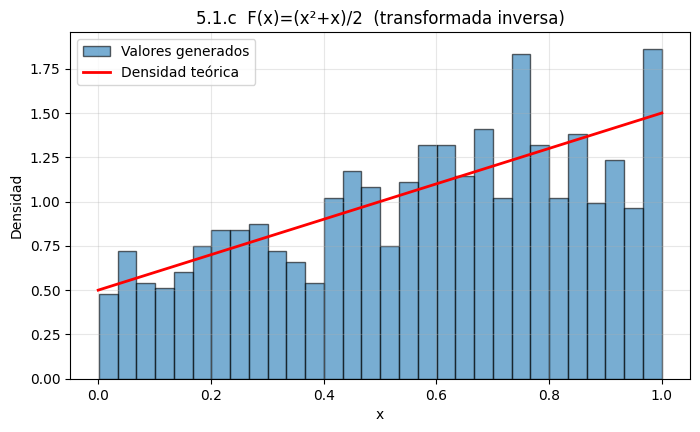

In [9]:
def gen_c_inversa():
    return (-1 + math.sqrt(1 + 8 * nextU())) / 2

xc = np.array([gen_c_inversa() for _ in range(n)])
x = np.linspace(0, 1, 300)
resumen(xc, 7 / 12)
print("Primeros 10 valores:", np.round(xc[:10], 4))
hist_vs_teorica(xc, x, x + 0.5, "5.1.c  F(x)=(x²+x)/2  (transformada inversa)")

### d. Variable aleatoria de Weibull

$$F(x)=1-\exp(-\alpha x^\beta),\qquad 0<x<\infty$$

**Transformada inversa.** De $u=1-e^{-\alpha x^\beta}$ se obtiene $-\log(1-u)=\alpha x^\beta$, y como $1-U$ también es uniforme en $(0,1)$ (igual que en el ejemplo de la exponencial):

$$X=\left(-\frac{1}{\alpha}\log U\right)^{1/\beta}.$$

La densidad es $f(x)=\alpha\beta x^{\beta-1}e^{-\alpha x^\beta}$. Se usan $\alpha=1,\ \beta=2$ y también $\alpha=0.5,\ \beta=1$; en este último caso la Weibull se reduce a una exponencial de tasa $\alpha$.

α = 1.0, β = 2.0
n = 1000 | media muestral = 0.9090
Primeros 10 valores: [0.931  0.4759 0.5286 0.8616 0.6452 1.042  1.1489 0.2362 1.0833 1.2382]


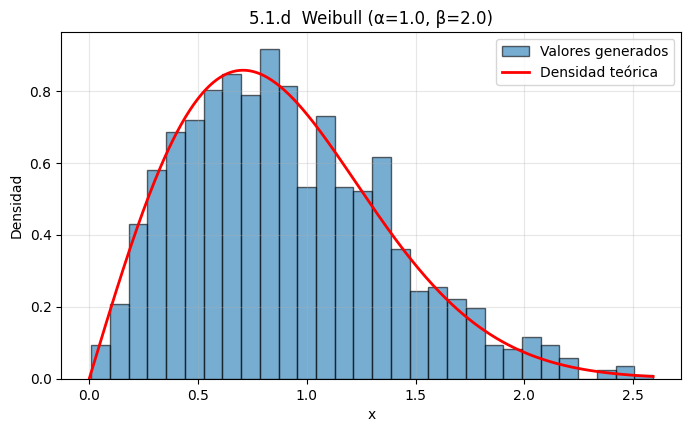

α = 0.5, β = 1.0
n = 1000 | media muestral = 1.9790
Primeros 10 valores: [0.6846 0.7164 1.7337 0.3709 2.867  1.6116 1.8862 0.9171 3.8949 6.6706]


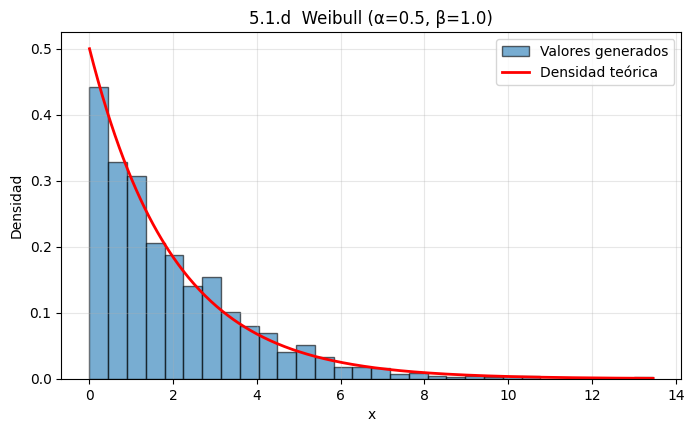

In [ ]:
def gen_weibull(alpha, beta):
    return (-math.log(nextU()) / alpha) ** (1 / beta)

def f_weibull(x, alpha, beta):
    return alpha * beta * x ** (beta - 1) * np.exp(-alpha * x ** beta)

for alpha_w, beta_w in [(1.0, 2.0), (0.5, 1.0)]:
    xd = np.array([gen_weibull(alpha_w, beta_w) for _ in range(n)])
    x = np.linspace(1e-3, xd.max(), 400)
    print(f"α = {alpha_w}, β = {beta_w}")
    resumen(xd)
    print("Primeros 10 valores:", np.round(xd[:10], 4))
    hist_vs_teorica(xd, x, f_weibull(x, alpha_w, beta_w), f"5.1.d  Weibull (α={alpha_w}, β={beta_w})")

## 5.2. Generando procesos de Poisson

### a. Primeras T unidades de tiempo de un proceso de Poisson con tasa λ

Como los tiempos entre eventos son exponenciales independientes con tasa $\lambda$, se suman hasta pasar de $T$:

1. $t=0,\ I=0$.
2. Generar un número aleatorio $U$.
3. $t=t-\frac1\lambda\log U$. Si $t>T$, parar.
4. $I=I+1,\ S(I)=t$.
5. Ir al paso 2.

Al final, $I$ es el número de eventos hasta $T$ y $S(1),\dots,S(I)$ son los tiempos de los eventos en orden creciente. Se usa $T=10$ y $\lambda=2$.

Número de eventos en [0, 10]: I = 23  (valor esperado λT = 20)
Tiempos de los eventos S(1..I):
[0.0209 0.2437 0.4458 0.6102 1.1172 1.171  1.6133 2.1863 2.3487 2.651
 4.3074 4.4783 4.497  4.8471 4.9303 5.5972 6.0925 7.8812 8.566  8.7477
 8.8398 9.3198 9.9051]


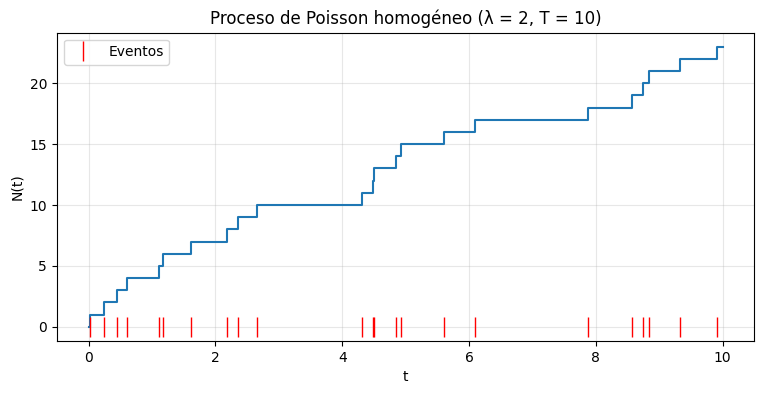

In [10]:
def proceso_poisson(T, lam):
    t, I, S = 0.0, 0, []
    while True:
        t = t - math.log(nextU()) / lam
        if t > T:
            break
        I += 1
        S.append(t)
    return I, S

T, lam = 10, 2
I, S = proceso_poisson(T, lam)
print(f"Número de eventos en [0, {T}]: I = {I}  (valor esperado λT = {lam*T})")
print("Tiempos de los eventos S(1..I):")
print(np.round(S, 4))

plt.figure(figsize=(9, 4))
plt.step([0] + S + [T], list(range(I + 1)) + [I], where="post")
plt.plot(S, np.zeros(I), "|", color="red", markersize=15, label="Eventos")
plt.title(f"Proceso de Poisson homogéneo (λ = {lam}, T = {T})")
plt.xlabel("t")
plt.ylabel("N(t)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Verificación.** Se repite la simulación 1000 veces. El promedio de $N(T)$ debe acercarse a $\lambda T$, y los tiempos entre eventos deben seguir una exponencial de tasa $\lambda$.

Promedio de N(T) = 19.9340 | λT = 20


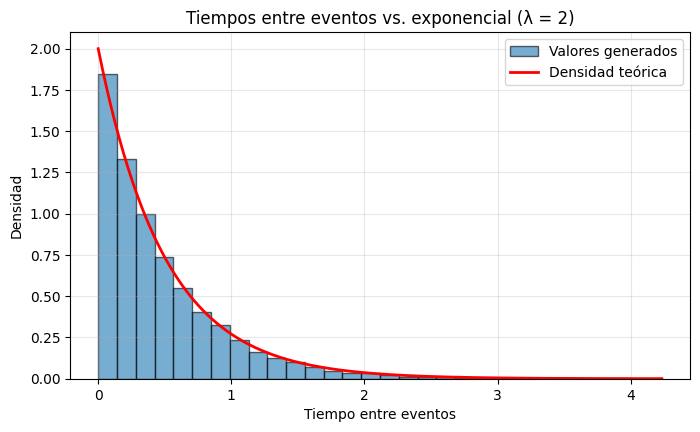

In [11]:
reps = 1000
conteos, entre = [], []
for _ in range(reps):
    I_r, S_r = proceso_poisson(T, lam)
    conteos.append(I_r)
    entre.extend(np.diff([0.0] + S_r))
conteos = np.array(conteos)
entre = np.array(entre)

print(f"Promedio de N(T) = {conteos.mean():.4f} | λT = {lam*T}")
x = np.linspace(0, entre.max(), 400)
hist_vs_teorica(entre, x, lam * np.exp(-lam * x), "Tiempos entre eventos vs. exponencial (λ = 2)", xlabel="Tiempo entre eventos")

### b. Variable aleatoria de Coxian

El trabajador pasa por $k$ etapas en secuencia. El tiempo en la etapa $i$ es exponencial con tasa $\lambda_i$ y, al terminarla, continúa a la siguiente con probabilidad $\alpha_i$ (se detiene con probabilidad $1-\alpha_i$). $X$ es el tiempo total trabajado.

**Algoritmo:**

1. $X=0,\ i=1$.
2. Generar $U$ y hacer $X=X-\frac{1}{\lambda_i}\log U$.
3. Si $i=k$, parar y retornar $X$.
4. Generar $U$. Si $U>\alpha_i$, parar y retornar $X$.
5. $i=i+1$ e ir al paso 2.

Para verificar, la media teórica suma la media de cada etapa por la probabilidad de llegar a ella:

$$E[X]=\sum_{i=1}^{k}\left(\prod_{j=1}^{i-1}\alpha_j\right)\frac{1}{\lambda_i}.$$

Se usan $k=3$, $\lambda=(1,2,3)$ y $\alpha=(0.8,\,0.6)$ para las etapas 1 y 2.

n = 1000 | media muestral = 1.5951 | media teórica = 1.5600
Terminó en la etapa 1: proporción = 0.194 | teórica = 0.200
Terminó en la etapa 2: proporción = 0.304 | teórica = 0.320
Terminó en la etapa 3: proporción = 0.502 | teórica = 0.480
Primeros 10 valores: [0.5051 1.5197 3.7064 0.4867 0.2681 1.0412 2.3533 1.8425 2.5247 1.2268]


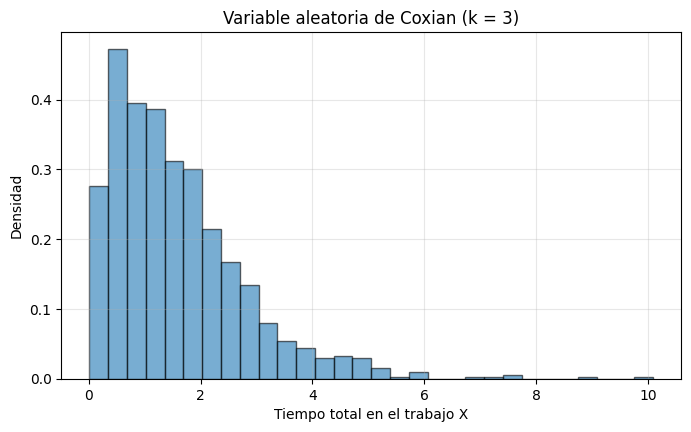

In [ ]:
def gen_coxian(lams, alphas):
    k = len(lams)
    X = 0.0
    for i in range(k):
        X += -math.log(nextU()) / lams[i]
        if i == k - 1:
            return X, i + 1
        if nextU() > alphas[i]:
            return X, i + 1

lams = [1.0, 2.0, 3.0]
alphas = [0.8, 0.6]

res = [gen_coxian(lams, alphas) for _ in range(n)]
xcox = np.array([r[0] for r in res])
etapas = np.array([r[1] for r in res])

media_teo, prob = 0.0, 1.0
for i, l in enumerate(lams):
    media_teo += prob / l
    if i < len(alphas):
        prob *= alphas[i]

resumen(xcox, media_teo)
p_teo = [1 - alphas[0], alphas[0] * (1 - alphas[1]), alphas[0] * alphas[1]]
for e in range(1, len(lams) + 1):
    print(f"Terminó en la etapa {e}: proporción = {np.mean(etapas == e):.3f} | teórica = {p_teo[e-1]:.3f}")
print("Primeros 10 valores:", np.round(xcox[:10], 4))

plt.figure(figsize=(8, 4.5))
plt.hist(xcox, bins=30, density=True, alpha=0.6, edgecolor="black")
plt.title("Variable aleatoria de Coxian (k = 3)")
plt.xlabel("Tiempo total en el trabajo X")
plt.ylabel("Densidad")
plt.grid(alpha=0.3)
plt.show()

## 5.3. Generando procesos de Poisson no homogéneos

Se generan las primeras 10 unidades de tiempo de un proceso con intensidad

$$\lambda(t)=\begin{cases}\dfrac{t}{5}, & 0<t<5\\[2mm] 1+5(t-5), & 5<t<10\end{cases}$$

La función es creciente, con máximo $\lambda(10)=26$. El número esperado de eventos en $[0,10]$ es

$$\int_0^{5}\frac t5\,dt+\int_5^{10}\big(1+5(t-5)\big)dt=2.5+67.5=70.$$

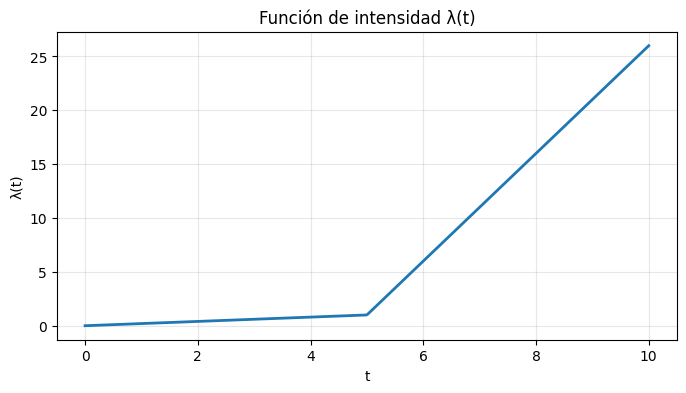

In [12]:
def lam_t(t):
    return t / 5 if t <= 5 else 1 + 5 * (t - 5)

T = 10
tt = np.linspace(0, T, 500)
plt.figure(figsize=(8, 4))
plt.plot(tt, [lam_t(v) for v in tt], lw=2)
plt.title("Función de intensidad λ(t)")
plt.xlabel("t")
plt.ylabel("λ(t)")
plt.grid(alpha=0.3)
plt.show()

### Método 1: adelgazamiento (*thinning*) con λ = 26

1. $t=0,\ I=0$.
2. Generar $U$.
3. $t=t-\frac1\lambda\log U$. Si $t>T$, parar.
4. Generar $U$.
5. Si $U\le\lambda(t)/\lambda$, fijar $I=I+1,\ S(I)=t$.
6. Ir al paso 2.

In [13]:
def pnh_thinning(lam_func, lam_max, T):
    t, I, S, candidatos = 0.0, 0, [], 0
    while True:
        t = t - math.log(nextU()) / lam_max
        if t > T:
            break
        candidatos += 1
        if nextU() <= lam_func(t) / lam_max:
            I += 1
            S.append(t)
    return I, S, candidatos

I1, S1, cand1 = pnh_thinning(lam_t, 26, T)
print(f"Eventos aceptados: {I1} | candidatos generados: {cand1} | rechazados: {cand1 - I1}")
print("Tiempos de los eventos:")
print(np.round(S1, 4))

Eventos aceptados: 88 | candidatos generados: 277 | rechazados: 189
Tiempos de los eventos:
[0.7794 1.4387 3.6688 4.1092 4.7874 5.2202 5.7335 5.8284 5.9236 6.0612
 6.0927 6.1625 6.5338 6.6771 6.6773 6.7135 6.7659 6.7995 6.8403 7.0812
 7.1522 7.1743 7.185  7.1941 7.2102 7.2454 7.3074 7.3175 7.6066 7.6082
 7.6109 7.6348 7.6389 7.7111 7.716  7.72   7.724  7.753  7.8824 7.8937
 7.9302 7.9548 7.9674 8.1081 8.144  8.1473 8.1885 8.2207 8.2317 8.2534
 8.2621 8.3513 8.421  8.553  8.8209 8.8337 8.8439 8.8679 8.9184 8.9365
 8.9923 9.1263 9.1983 9.245  9.2465 9.2486 9.2925 9.3387 9.3549 9.3769
 9.4166 9.4953 9.6521 9.6535 9.6625 9.6739 9.689  9.7009 9.7353 9.7372
 9.7605 9.8019 9.8272 9.8603 9.8632 9.9067 9.9214 9.9664]


### Método 2: adelgazamiento por subintervalos

El método anterior desperdicia muchos candidatos porque $\lambda(t)$ está lejos de 26 en casi todo el intervalo. Siguiendo la mejora de la sección 5.5, se divide $[0,10]$ en subintervalos con una cota $\lambda_j\ge\lambda(s)$ en cada uno:

| Subintervalo | $[0,5)$ | $[5,6)$ | $[6,7)$ | $[7,8)$ | $[8,9)$ | $[9,10]$ |
|---|---|---|---|---|---|---|
| $\lambda_j$ | 1 | 6 | 11 | 16 | 21 | 26 |

Cada $\lambda_j$ es el valor de $\lambda(t)$ en el extremo derecho del subintervalo, porque la función es creciente. Algoritmo ($t$ tiempo actual, $J$ subintervalo actual, $I$ número de eventos):

1. $t=0,\ J=1,\ I=0$.
2. Generar $U$ y fijar $X=-\frac{1}{\lambda_J}\log U$.
3. Si $t+X>t_J$, ir al paso 8.
4. $t=t+X$.
5. Generar $U$.
6. Si $U\le\lambda(t)/\lambda_J$, fijar $I=I+1,\ S(I)=t$.
7. Ir al paso 2.
8. Si $J=k+1$, parar.
9. $X=(X-t_J+t)\lambda_J/\lambda_{J+1},\ t=t_J,\ J=J+1$.
10. Ir al paso 3.

El paso 9 reaprovecha el exponencial sobrante gracias a la falta de memoria de la exponencial.

Eventos aceptados: 68 | candidatos generados: 81 | rechazados: 13
Tiempos de los eventos:
[0.9205 1.4584 3.8501 4.8394 5.3346 5.7662 5.7891 5.8554 5.9227 5.9823
 6.0066 6.0158 6.0393 6.0543 6.48   6.576  6.8045 6.8593 6.9475 7.0268
 7.2246 7.4384 7.5784 7.5934 7.6032 7.6064 7.6733 7.7488 7.8235 7.8611
 7.8886 7.9861 7.9874 8.0059 8.1443 8.1447 8.2461 8.2527 8.2971 8.3157
 8.4076 8.5551 8.6918 8.6976 8.7111 8.7716 8.7914 8.8548 8.8947 8.9285
 9.0374 9.0375 9.0529 9.1272 9.215  9.2567 9.2772 9.3527 9.3992 9.4155
 9.5126 9.6058 9.6864 9.784  9.9529 9.9608 9.9838 9.9983]


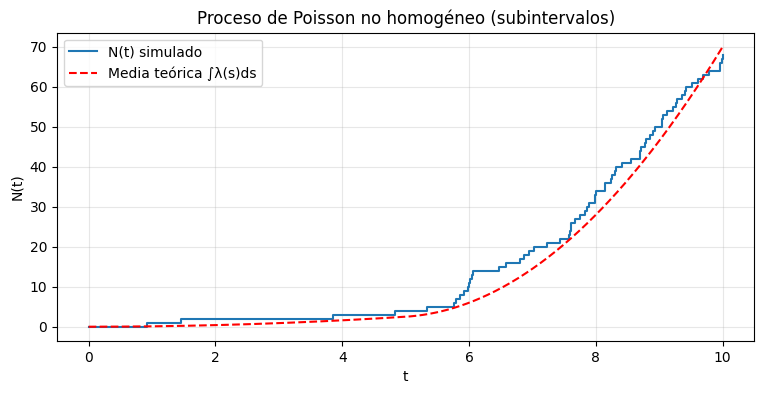

In [ ]:
def pnh_subintervalos(lam_func, tj, lamj):
    k1 = len(tj)
    t, J, I, S, candidatos = 0.0, 0, 0, [], 0
    X = -math.log(nextU()) / lamj[J]
    while True:
        if t + X > tj[J]:
            if J == k1 - 1:
                break
            X = (X - tj[J] + t) * lamj[J] / lamj[J + 1]
            t = tj[J]
            J += 1
            continue
        t = t + X
        candidatos += 1
        if nextU() <= lam_func(t) / lamj[J]:
            I += 1
            S.append(t)
        X = -math.log(nextU()) / lamj[J]
    return I, S, candidatos

tj = [5, 6, 7, 8, 9, 10]
lamj = [1, 6, 11, 16, 21, 26]

I2, S2, cand2 = pnh_subintervalos(lam_t, tj, lamj)
print(f"Eventos aceptados: {I2} | candidatos generados: {cand2} | rechazados: {cand2 - I2}")
print("Tiempos de los eventos:")
print(np.round(S2, 4))

plt.figure(figsize=(9, 4))
plt.step([0] + S2 + [T], list(range(I2 + 1)) + [I2], where="post", label="N(t) simulado")
plt.plot(tt, [2.5 * (v / 5) ** 2 if v <= 5 else 2.5 + (v - 5) + 2.5 * (v - 5) ** 2 for v in tt],
         "r--", label="Media teórica ∫λ(s)ds")
plt.title("Proceso de Poisson no homogéneo (subintervalos)")
plt.xlabel("t")
plt.ylabel("N(t)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Verificación y comparación de eficiencia

Se repiten ambos métodos 500 veces. Se compara el promedio de $N(10)$ con el valor esperado 70 y el número promedio de candidatos evaluados, y se estima la intensidad a partir de los tiempos de los eventos contra $\lambda(t)$.

Thinning (λ = 26)    | media N(10) =  69.974 (teórico 70) | candidatos promedio =  259.38 | aceptación = 0.270
Subintervalos        | media N(10) =  69.550 (teórico 70) | candidatos promedio =   84.56 | aceptación = 0.822


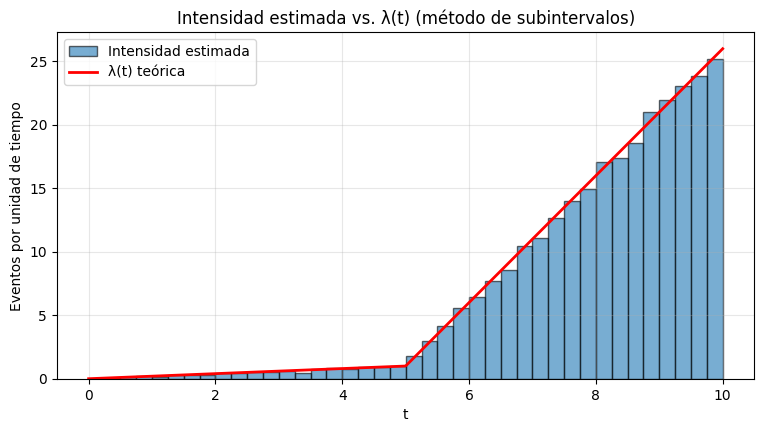

Números aleatorios usados en todo el notebook: 382819 de 1000000


In [ ]:
reps = 500
res1 = [pnh_thinning(lam_t, 26, T) for _ in range(reps)]
res2 = [pnh_subintervalos(lam_t, tj, lamj) for _ in range(reps)]

for nombre, res in [("Thinning (λ = 26)", res1), ("Subintervalos", res2)]:
    N_ev = np.array([r[0] for r in res])
    cand = np.array([r[2] for r in res])
    print(f"{nombre:20s} | media N(10) = {N_ev.mean():7.3f} (teórico 70) | "
          f"candidatos promedio = {cand.mean():7.2f} | aceptación = {N_ev.sum()/cand.sum():.3f}")

tiempos = np.concatenate([r[1] for r in res2])
bins = np.linspace(0, T, 41)
ancho = bins[1] - bins[0]
plt.figure(figsize=(9, 4.5))
plt.hist(tiempos, bins=bins, weights=np.full(len(tiempos), 1 / (reps * ancho)),
         alpha=0.6, edgecolor="black", label="Intensidad estimada")
plt.plot(tt, [lam_t(v) for v in tt], "r-", lw=2, label="λ(t) teórica")
plt.title("Intensidad estimada vs. λ(t) (método de subintervalos)")
plt.xlabel("t")
plt.ylabel("Eventos por unidad de tiempo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Números aleatorios usados en todo el notebook: {pos} de {N_U}")

Ambos métodos generan el mismo proceso, pues el promedio de $N(10)$ se acerca a 70 y la intensidad estimada sigue a $\lambda(t)$. La diferencia está en la eficiencia. Con $\lambda=26$ fijo se generan en promedio unos $26\times10=260$ candidatos para aceptar cerca de 70, mientras que con las cotas por tramos se generan alrededor de $1\cdot5+6+11+16+21+26=85$. Esto confirma lo que plantea Ross, el adelgazamiento es más eficiente cuanto más cerca está $\lambda(t)$ de la cota usada.